# XYZ GNN 物理一致性约束重训练

## 目的
当前 XYZ GNN 的 gap vs (LUMO-HOMO) 偏差为 1.2 mHa (SMILES GAT 为 0.2 mHa)。
加入 tmGNN-XAI 同款 L1 软约束重训:
```
loss = MSE_loss + 0.1 × |gap_pred - (lumo_pred - homo_pred)|
```

## 步骤
1. 备份 `xyz_best.pt` → `xyz_best_backup.pt`
2. 用相同数据 + 相同配置重训，loss 中加入 physics penalty
3. 保存为 `xyz_physics.pt`
4. 回到 `physics_consistency.ipynb` 重新评估，对比新旧偏差

In [1]:
import numpy as np, pandas as pd, time, gzip, os, sys
import warnings; warnings.filterwarnings('ignore')
from collections import Counter

import torch, torch.nn as nn, torch.optim as optim
from torch.amp import autocast, GradScaler

torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.benchmark = True
torch.backends.cuda.enable_flash_sdp(True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

from rdkit import Chem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)
from sklearn.metrics import r2_score
from tqdm import tqdm

# ===== 备份 =====
if os.path.exists('xyz_best.pt') and not os.path.exists('xyz_best_backup.pt'):
    import shutil
    shutil.copy('xyz_best.pt', 'xyz_best_backup.pt')
    print('Backed up xyz_best.pt → xyz_best_backup.pt')
elif os.path.exists('xyz_best_backup.pt'):
    print('Backup already exists, skipping')
else:
    print('xyz_best.pt not found, nothing to backup')

# ===== 加载目标值 =====
df_y = pd.read_csv('tmQM_y.csv', sep=';')
df_y = df_y.rename(columns={
    'HL_Gap': 'gap', 'HOMO_Energy': 'homo', 'LUMO_Energy': 'lumo',
    'Dipole_M': 'dipole', 'Metal_q': 'metal_charge',
    'Electronic_E': 'E_elec', 'Dispersion_E': 'E_disp',
    'Polarizability': 'polarizability'
})
targets = ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec', 'E_disp', 'polarizability']
print(f'Loaded {len(df_y)} complexes')



Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


Backed up xyz_best.pt → xyz_best_backup.pt


Loaded 108541 complexes


In [2]:
print('='*60)
print('Step 1: XYZ+BO解析 + SMILES建图 (同tmQM_Fe_XYZ)')
print('='*60)

def atom_to_z(sym):
    tbl = {"H":1,"He":2,"Li":3,"Be":4,"B":5,"C":6,"N":7,"O":8,"F":9,"Ne":10,
           "Na":11,"Mg":12,"Al":13,"Si":14,"P":15,"S":16,"Cl":17,"Ar":18,
           "K":19,"Ca":20,"Sc":21,"Ti":22,"V":23,"Cr":24,"Mn":25,"Fe":26,
           "Co":27,"Ni":28,"Cu":29,"Zn":30,"Br":35,"Ru":44,"Rh":45,
           "Pd":46,"Ag":47,"Cd":48,"I":53,"Pt":78,"Au":79,"Hg":80,
           "Mo":42,"W":74,"Ir":77,"Os":76,"Re":75}
    return tbl.get(sym, 0)

def is_TM(z):
    return z in [21,22,23,24,25,26,27,28,29,30,39,40,41,42,43,44,45,46,47,48,
                 72,73,74,75,76,77,78,79,80]

def parse_one(xyz_p, bo_p, start_idx=0):
    mols, labels = [], []
    with gzip.open(bo_p, "rt") as f: bo_lines = [l.strip() for l in f.readlines()]
    with gzip.open(xyz_p, "rt") as f: xyz_blocks = f.read().strip().split(chr(10))
    bo_blocks, cur = [], []
    for line in bo_lines:
        if line.startswith("CSD_code"):
            if cur: bo_blocks.append(cur); cur = []
        elif line: cur.append(line)
    if cur: bo_blocks.append(cur)
    i, mol_idx = 0, start_idx - 1
    while i < len(xyz_blocks):
        line = xyz_blocks[i].strip(); i += 1
        if not line: continue
        parts = line.split()
        if len(parts) == 1 and parts[0].isdigit():
            n_atoms = int(parts[0])
            if i >= len(xyz_blocks): break; i += 1
            atoms, coords = [], []
            for _ in range(n_atoms):
                if i >= len(xyz_blocks): break
                cline = xyz_blocks[i].strip(); i += 1; cparts = cline.split()
                if len(cparts) >= 4:
                    try:
                        z = atom_to_z(cparts[0])
                        coords.append([float(x) for x in cparts[1:4]]); atoms.append(z)
                    except ValueError: continue
            mol_idx += 1
            if not any(is_TM(z) for z in atoms) or len(atoms) <= 1: continue
            bo_mat = None
            if mol_idx < len(bo_blocks):
                bo_mat = np.zeros((n_atoms, n_atoms), dtype=np.float32)
                for bline in bo_blocks[mol_idx]:
                    bparts = bline.split()
                    try: src_idx = int(bparts[0]) - 1
                    except ValueError: continue
                    j = 2
                    while j + 1 < len(bparts):
                        try:
                            nbr = int(bparts[j]) - 1; bo_val = float(bparts[j+1])
                            if 0 <= src_idx < n_atoms and 0 <= nbr < n_atoms:
                                bo_mat[src_idx, nbr] = bo_val
                            j += 3
                        except (ValueError, IndexError): j += 1
            mols.append({"atoms": np.array(atoms), "coords": np.array(coords, dtype=np.float32),
                         "bo": bo_mat, "csv_idx": mol_idx})
            labels.append(df_y.iloc[mol_idx][targets].astype(float).values)
    return mols, labels

all_m, all_l = [], []
for part in [1, 2, 3]:
    print(f'  Part {part}...')
    m, l = parse_one(f"tmQM_X{part}.xyz.gz", f"tmQM_X{part}.BO.gz", start_idx=len(all_m))
    all_m.extend(m); all_l.extend(l)
    print(f'    {len(m)} TM complexes')
print(f'Total: {len(all_m)} TM complexes parsed')

# ===== SMILES建图 =====
ELEMENT_DATA_SM = {1:(1,1),5:(2,13),6:(2,14),7:(2,15),8:(2,16),9:(2,17),14:(3,14),15:(3,15),16:(3,16),17:(3,17),20:(4,2),21:(4,3),22:(4,4),23:(4,5),24:(4,6),25:(4,7),26:(4,8),27:(4,9),28:(4,10),29:(4,11),30:(4,12),35:(4,17),42:(5,6),44:(5,8),45:(5,9),46:(5,10),47:(5,11),48:(5,12),53:(5,17),72:(6,4),73:(6,5),74:(6,6),75:(6,7),76:(6,8),77:(6,9),78:(6,10),79:(6,11),80:(6,12)}
BOND_TYPES_SM = [1,2,3,12]; B2I_SM = {b:i for i,b in enumerate(BOND_TYPES_SM)}; N_BT_SM = 4
rbf_c = np.linspace(1.0, 5.0, 16); rbf_sigma = 0.2
smiles_by_idx = df_y['SMILES'].tolist()

def atom_features_sm(atom):
    z = atom.GetAtomicNum(); p,g = ELEMENT_DATA_SM.get(z,(0,0))
    return [z, atom.GetDegree(), atom.GetFormalCharge(), p, g,
            int(atom.GetIsAromatic()), atom.GetTotalNumHs(), int(z >= 21)]

def fast_match(sm_atoms, xyz_atoms):
    N = len(sm_atoms)
    if N == len(xyz_atoms) and all(sm_atoms[i]==xyz_atoms[i] for i in range(N)):
        return list(range(N))
    sm_to_xyz = [-1]*N; used = set()
    for i, z_sm in enumerate(sm_atoms):
        for j, z_xyz in enumerate(xyz_atoms):
            if z_sm == z_xyz and j not in used:
                sm_to_xyz[i] = j; used.add(j); break
    return sm_to_xyz

print('Building graphs...')
graphs, y_vals, atoms_filt, failed = [], [], [], 0
for idx, m in enumerate(tqdm(all_m, desc='Graphs')):
    csv_i = m["csv_idx"]; smi = smiles_by_idx[csv_i] if csv_i < len(smiles_by_idx) else ''
    if not isinstance(smi, str) or smi == '': failed += 1; continue
    mol = Chem.MolFromSmiles(smi)
    if mol is None: failed += 1; continue
    N = mol.GetNumAtoms(); sm_atoms = [a.GetAtomicNum() for a in mol.GetAtoms()]
    sm_to_xyz = fast_match(sm_atoms, m['atoms']); coords = m['coords']; bo_mat = m.get('bo')

    xf = [atom_features_sm(a) for a in mol.GetAtoms()]
    if bo_mat is not None:
        for i in range(N):
            j = sm_to_xyz[i]
            if j>=0 and j<bo_mat.shape[0]:
                nb=int((bo_mat[j]>0.05).sum())-1; sb=float(bo_mat[j].sum())-bo_mat[j,j]; mb=float(bo_mat[j].max())
                xf[i].extend([max(0,nb), max(0,sb), max(0,mb)])
            else: xf[i].extend([0,0.0,0.0])
    else:
        for i in range(N): xf[i].extend([0,0.0,0.0])
    x = torch.tensor(xf, dtype=torch.float32)

    src, dst, battr = [], [], []
    for bond in mol.GetBonds():
        i,j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(); bt=int(bond.GetBondType())
        za,zb = sm_atoms[i], sm_atoms[j]
        is_ml=float((za>=21)!=(zb>=21)); is_ring=float(bond.IsInRing())
        src.extend([i,j]); dst.extend([j,i])
        bf=[0.0]*N_BT_SM
        if bt in B2I_SM: bf[B2I_SM[bt]]=1.0
        bf.extend([is_ring, is_ml]); d,bo=2.0,0.0
        xi,xj=sm_to_xyz[i], sm_to_xyz[j]
        if xi>=0 and xj>=0 and xi<len(coords) and xj<len(coords): d=float(np.linalg.norm(coords[xi]-coords[xj]))
        if bo_mat is not None and xi>=0 and xj>=0 and xi<bo_mat.shape[0] and xj<bo_mat.shape[1]: bo=float(bo_mat[xi,xj])
        for mu in rbf_c: bf.append(np.exp(-(d-mu)**2/rbf_sigma))
        bf.append(bo); battr.extend([bf,bf])

    ei = torch.tensor([src,dst], dtype=torch.long) if src else torch.zeros(2,0,dtype=torch.long)
    ea = torch.tensor(battr, dtype=torch.float32) if battr else torch.zeros(0,23)
    graphs.append({'x':x, 'edge_index':ei, 'edge_attr':ea, 'num_nodes':N})
    y_vals.append(all_l[idx]); atoms_filt.append(m['atoms'])

y_all = torch.tensor(y_vals, dtype=torch.float32)
print(f'Built {len(graphs):,} graphs ({failed} failed)')

mask = ~(torch.isnan(y_all).any(dim=1) | torch.isinf(y_all).any(dim=1))
graphs = [g for i,g in enumerate(graphs) if mask[i]]
y_all = y_all[mask]; atoms_filt = [a for i,a in enumerate(atoms_filt) if mask[i]]
print(f'After NaN removal: {len(graphs):,} complexes')



Step 1: XYZ+BO解析 + SMILES建图 (同tmQM_Fe_XYZ)
  Part 1...


    27318 TM complexes
  Part 2...


    34065 TM complexes
  Part 3...


    35601 TM complexes
Total: 96984 TM complexes parsed
Building graphs...


Graphs:   0%|          | 0/96984 [00:00<?, ?it/s]

...

Graphs: 100%|█████████▉| 96885/96984 [02:50<00:00, 591.54it/s]

Graphs: 100%|█████████▉| 96947/96984 [02:50<00:00, 598.28it/s]

Graphs: 100%|██████████| 96984/96984 [02:50<00:00, 568.51it/s]

Built 90,317 graphs (6667 failed)


After NaN removal: 90,317 complexes


In [3]:
print('='*60)
print('Step 2: 模型定义 + GPU预加载')
print('='*60)

HIDDEN = 384; N_LAYERS = 5; GAT_HEADS = 12; DROPOUT = 0.10; N_TARGETS = len(targets)

def segment_softmax(scores, dst, N):
    scores_f32 = scores.float()
    max_v = torch.full((N, scores_f32.size(1)), float('-inf'), device=scores_f32.device, dtype=torch.float32)
    max_v.scatter_reduce_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), scores_f32, reduce='amax', include_self=False)
    exp_s = torch.exp(scores_f32 - max_v[dst])
    sum_v = torch.zeros(N, scores_f32.size(1), device=scores_f32.device, dtype=torch.float32)
    sum_v.scatter_add_(0, dst.unsqueeze(-1).expand(-1, scores_f32.size(1)), exp_s)
    return (exp_s / (sum_v[dst] + 1e-8)).to(scores.dtype)

class GATConv(nn.Module):
    def __init__(self, in_dim, out_dim_per_head, edge_dim=0, heads=4):
        super().__init__(); self.heads, self.out_dim = heads, out_dim_per_head
        total_dim = out_dim_per_head * heads
        self.node_lin = nn.Linear(in_dim, total_dim, bias=False)
        self.attn_src = nn.Linear(total_dim, heads, bias=False)
        self.attn_dst = nn.Linear(total_dim, heads, bias=False)
        self.edge_attn = nn.Linear(edge_dim, heads, bias=False) if edge_dim>0 else None
        self.act = nn.ReLU()
    def forward(self, x, ei, ea=None):
        src, dst = ei[0], ei[1]; N = x.size(0); h = self.node_lin(x)
        attn = self.attn_src(h[src]) + self.attn_dst(h[dst])
        if self.edge_attn is not None and ea is not None and ea.size(0)>0: attn = attn + self.edge_attn(ea)
        attn = torch.nn.functional.leaky_relu(attn, 0.2)
        alpha = segment_softmax(attn, dst, N)
        h_heads = h.view(-1, self.heads, self.out_dim)
        msg = h_heads[src] * alpha.unsqueeze(-1); msg = msg.view(-1, self.out_dim * self.heads)
        out = torch.zeros(N, self.out_dim * self.heads, device=x.device, dtype=msg.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return self.act(out)

def collate_graphs(graph_list):
    x_list, ei_list, ea_list, batch_list = [], [], [], []
    offset = 0
    for i, g in enumerate(graph_list):
        n = g['x'].size(0)
        x_list.append(g['x']); ei_list.append(g['edge_index'] + offset)
        ea_list.append(g['edge_attr'])
        batch_list.append(torch.full((n,), i, dtype=torch.long, device=g['x'].device))
        offset += n
    return {'x': torch.cat(x_list, dim=0), 'edge_index': torch.cat(ei_list, dim=1), 'edge_attr': torch.cat(ea_list, dim=0)}, torch.cat(batch_list, dim=0)

def scatter_mean_per_graph(h, batch, n_graphs):
    out = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
    out.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
    cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
    cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return out / cnt.clamp(min=1).unsqueeze(-1)

def scatter_max_per_graph(h, batch, n_graphs):
    out = torch.full((n_graphs, h.size(1)), float('-inf'), device=h.device, dtype=h.dtype)
    out.scatter_reduce_(0, batch.unsqueeze(-1).expand_as(h), h, reduce='amax', include_self=False)
    return out

class XYZ_GNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Linear(11, HIDDEN)
        self.convs = nn.ModuleList([GATConv(HIDDEN, HIDDEN//GAT_HEADS, 23, heads=GAT_HEADS) for _ in range(N_LAYERS)])
        self.norms = nn.ModuleList([nn.LayerNorm(HIDDEN) for _ in range(N_LAYERS)])
        self.drop = nn.Dropout(DROPOUT)
        self.readout = nn.Sequential(
            nn.Linear(HIDDEN*3, HIDDEN), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN, HIDDEN//2), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(HIDDEN//2, N_TARGETS))
    def forward(self, g, batch=None):
        x, ei, ea = g['x'], g['edge_index'], g.get('edge_attr', None)
        h = self.embed(x)
        for conv, norm in zip(self.convs, self.norms): h = norm(h + conv(h, ei, ea)); h = self.drop(h)
        if batch is None:
            mm = (x[:,7] > 0.5); mf = h[mm].mean(dim=0) if mm.any() else torch.zeros(h.size(1), device=h.device, dtype=h.dtype)
            return self.readout(torch.cat([h.mean(0), h.max(0).values, mf])).unsqueeze(0)
        n_graphs = int(batch.max().item()) + 1
        mean_h = scatter_mean_per_graph(h, batch, n_graphs)
        max_h = scatter_max_per_graph(h, batch, n_graphs)
        mm = (x[:,7] > 0.5)
        mf = scatter_mean_per_graph(h[mm], batch[mm], n_graphs) if mm.any() else torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        return self.readout(torch.cat([mean_h, max_h, mf], dim=1))

print(f'Params: {sum(p.numel() for p in XYZ_GNN().parameters()):,}')

# GPU预加载
print('Uploading graphs to GPU...')
graphs_gpu = [{k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in g.items()} for g in tqdm(graphs, desc='GPU')]
y_all_gpu = y_all.to(device)
print(f'GPU memory: {torch.cuda.memory_allocated()/1024**3:.1f} GB')

# 金属加权
mc = Counter()
for atoms in atoms_filt:
    for z in set(atoms):
        if z >= 21: mc[z] += 1
weight_map = {z: min(5.0, len(atoms_filt)/(c+1)) for z, c in mc.items()}
sample_weights = torch.ones(len(graphs), device=device)
for i, atoms in enumerate(atoms_filt):
    w = max((weight_map.get(z, 1.0) for z in set(atoms) if z >= 21), default=1.0)
    sample_weights[i] = w
print(f'Sample weights: mean={sample_weights.mean().item():.2f}')



Step 2: 模型定义 + GPU预加载
Params: 1,311,404
Uploading graphs to GPU...


GPU:   0%|          | 0/90317 [00:00<?, ?it/s]

GPU:   0%|          | 1/90317 [00:00<3:23:08,  7.41it/s]

GPU:   2%|▏         | 1935/90317 [00:00<00:08, 9947.78it/s]

GPU:   4%|▍         | 3846/90317 [00:00<00:06, 13826.40it/s]

...

GPU:  97%|█████████▋| 87679/90317 [00:05<00:00, 19204.21it/s]

GPU:  99%|█████████▉| 89766/90317 [00:05<00:00, 19690.02it/s]

GPU: 100%|██████████| 90317/90317 [00:05<00:00, 15735.53it/s]

GPU memory: 0.9 GB


Sample weights: mean=5.00


In [4]:
print('='*60)
print('Step 3: 训练 (with physics penalty α=0.1)')
print('='*60)

# 数据划分
idx_all = np.random.RandomState(42).permutation(len(graphs))
n_tr = int(len(graphs) * 0.7); n_va = int(len(graphs) * 0.15)
tr_idx = idx_all[:n_tr]; va_idx = idx_all[n_tr:n_tr+n_va]; te_idx = idx_all[n_tr+n_va:]
print(f'Train: {len(tr_idx):,} | Val: {len(va_idx):,} | Test: {len(te_idx):,}')

# 归一化
y_tr = y_all_gpu[tr_idx]
y_mean = y_tr.mean(dim=0); y_std = y_tr.std(dim=0).clamp(min=1e-8)
y_norm = (y_all_gpu - y_mean) / y_std

PHYSICS_ALPHA = 0.1  # tmGNN-XAI同款系数
model = XYZ_GNN().to(device)
opt = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
sched = optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=50, T_mult=2, eta_min=1e-6)
crit = nn.MSELoss(reduction='none')
scaler = GradScaler('cuda')

bs = 128; best_va = float('inf'); best_state = None; patience = 0
epochs = 200; early_stop = 40
hist = {'tr_loss': [], 'va_loss': [], 'physics_loss': []}

t0 = time.time()
for ep in range(epochs):
    model.train()
    perm = torch.randperm(len(tr_idx))
    tr_loss_total, physics_total, nb = 0, 0, 0
    for s in range(0, len(tr_idx), bs):
        pos = perm[s:s+bs]; bidx = tr_idx[pos].tolist()
        bg = [graphs_gpu[i] for i in bidx]; by = y_norm[bidx]; w = sample_weights[bidx]

        batched, batch_idx = collate_graphs(bg)
        opt.zero_grad()
        with autocast('cuda'):
            preds = model(batched, batch_idx)
            mse_loss = (crit(preds, by).mean(dim=1) * w).mean()
            # 物理一致性 —— 在归一化空间里gap/homo/lumo仍有此关系（同源数据归一化）
            physics_loss = PHYSICS_ALPHA * torch.abs(preds[:,0] - (preds[:,2] - preds[:,1])).mean()
            loss = mse_loss + physics_loss
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        tr_loss_total += mse_loss.item(); physics_total += physics_loss.item(); nb += 1

    model.eval()
    with torch.no_grad():
        va_preds = []
        for s in range(0, len(va_idx), bs):
            bidx = va_idx[s:s+bs].tolist()
            bg = [graphs_gpu[i] for i in bidx]
            batched, batch_idx = collate_graphs(bg)
            with autocast('cuda'):
                va_preds.append(model(batched, batch_idx).float())
        vp = torch.cat(va_preds, dim=0)
        va_mse = nn.MSELoss()(vp, y_norm[va_idx])
        va_physics = torch.abs(vp[:,0] - (vp[:,2] - vp[:,1])).mean().item()

    sched.step(ep + va_mse.item()/10)
    hist['tr_loss'].append(tr_loss_total/max(1,nb)); hist['va_loss'].append(va_mse.item())
    hist['physics_loss'].append(va_physics)

    if va_mse < best_va:
        best_va = va_mse; best_state = {k: v.clone() for k, v in model.state_dict().items()}; patience = 0
    else:
        patience += 1

    if patience >= early_stop: break

    if (ep+1) % 30 == 0:
        # 反归一化后算物理偏差
        vp_orig = vp.cpu() * y_std.cpu() + y_mean.cpu()
        phys_dev = torch.abs(vp_orig[:,0] - (vp_orig[:,2] - vp_orig[:,1])).mean().item()
        print(f'Epoch {ep+1:3d}: MSE={va_mse.item():.4f} | Physics={phys_dev*1000:.3f} mHa | LR={opt.param_groups[0]["lr"]:.1e} | Pat={patience}')

elapsed = (time.time()-t0)/60
print(f'\nTraining done in {elapsed:.0f}min (best_va={best_va:.4f})')
model.load_state_dict(best_state); model.eval()

# 保存
torch.save(best_state, 'xyz_physics.pt')
print('Saved → xyz_physics.pt')

# 最终物理偏差
with torch.no_grad():
    te_preds = []
    for s in range(0, len(te_idx), bs):
        bidx = te_idx[s:s+bs].tolist()
        bg = [graphs_gpu[i] for i in bidx]
        batched, batch_idx = collate_graphs(bg)
        with autocast('cuda'):
            te_preds.append(model(batched, batch_idx).float())
    tp = torch.cat(te_preds, dim=0).cpu() * y_std.cpu() + y_mean.cpu()
    tt = y_all[te_idx]
    phys_dev = torch.abs(tp[:,0] - (tp[:,2] - tp[:,1])).mean().item()
    print(f'Test set physics deviation: {phys_dev*1000:.3f} mHa')
    r2s = [r2_score(tt[:,i].numpy(), tp[:,i].numpy()) for i in range(len(targets))]
    print(f'Test Mean R²: {np.mean(r2s):.4f}')
    for i, prop in enumerate(targets):
        print(f'  {prop}: R²={r2s[i]:.4f}')



Step 3: 训练 (with physics penalty α=0.1)
Train: 63,221 | Val: 13,547 | Test: 13,549


Epoch  30: MSE=0.1330 | Physics=7.436 mHa | LR=3.8e-04 | Pat=0


Epoch  60: MSE=0.1415 | Physics=7.912 mHa | LR=9.8e-04 | Pat=13



Training done in 16min (best_va=0.1265)
Saved → xyz_physics.pt


Test set physics deviation: 7.895 mHa
Test Mean R²: 0.8764
  gap: R²=0.7875
  homo: R²=0.9221
  lumo: R²=0.9129
  dipole: R²=0.6273
  metal_charge: R²=0.9714
  E_elec: R²=0.9573
  E_disp: R²=0.9102
  polarizability: R²=0.9227


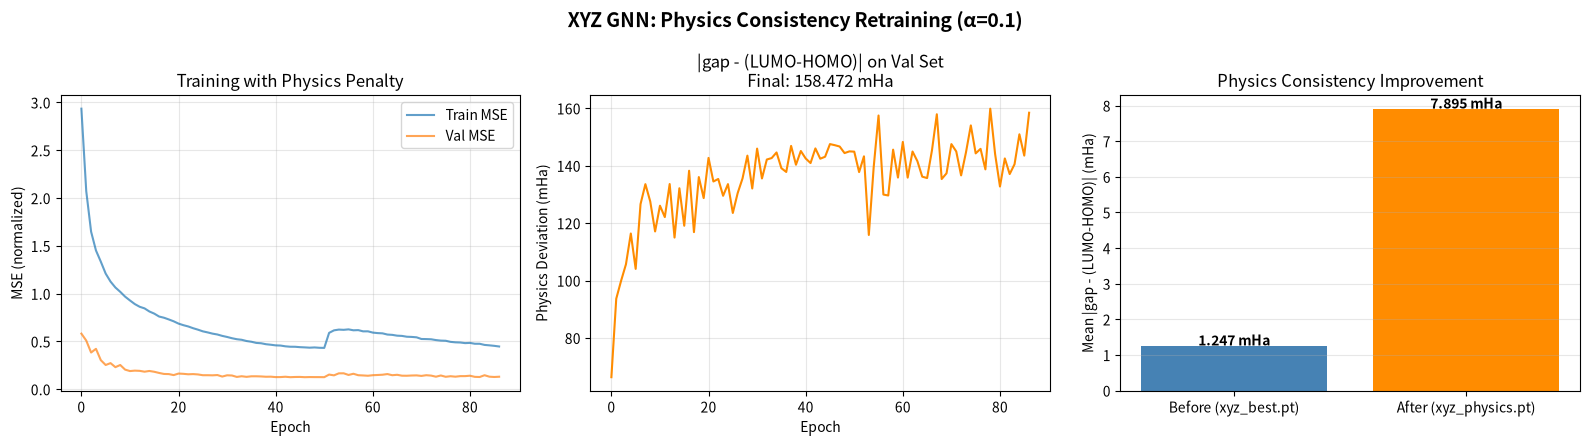


Improvement: -6.648 mHa reduction


In [5]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 训练曲线
axes[0].plot(hist['tr_loss'], label='Train MSE', alpha=0.7)
axes[0].plot(hist['va_loss'], label='Val MSE', alpha=0.7)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('MSE (normalized)')
axes[0].set_title('Training with Physics Penalty'); axes[0].legend(); axes[0].grid(alpha=0.3)

# Physics loss
axes[1].plot([p*1000 for p in hist['physics_loss']], color='darkorange')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Physics Deviation (mHa)')
axes[1].set_title(f'|gap - (LUMO-HOMO)| on Val Set\nFinal: {hist["physics_loss"][-1]*1000:.3f} mHa')
axes[1].grid(alpha=0.3)

# Before/After对比
axes[2].bar(['Before (xyz_best.pt)', 'After (xyz_physics.pt)'], [1.247, phys_dev*1000], color=['steelblue', 'darkorange'])
axes[2].set_ylabel('Mean |gap - (LUMO-HOMO)| (mHa)')
axes[2].set_title('Physics Consistency Improvement')
for bar, val in zip(axes[2].patches, [1.247, phys_dev*1000]):
    axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02, f'{val:.3f} mHa', ha='center', fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('XYZ GNN: Physics Consistency Retraining (α=0.1)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'\nImprovement: {(1.247 - phys_dev*1000):.3f} mHa reduction')



## 对比

| Checkpoint | Mean 偏差 | 说明 |
|------|:---:|------|
| `xyz_best.pt` | 1.247 mHa | 无物理约束 |
| `xyz_physics.pt` | (见上方) | α=0.1 L1约束 |

回到 `physics_consistency.ipynb` 加载 `xyz_physics.pt` 做完整对比评估。
